# Bird Species Classification — COSC 434 Group 12
Mohamed Alromaithi (`100060448`) · Zayed Alnuaimi (`100061300`)

We compare five pipelines on **CUB-200-2011** (`11,788` images, `200` species):
1. `RGB_LR` — 48-bin RGB colour histogram + Logistic Regression (simple baseline)
2. `HSV_SVM` — 512-bin joint HSV histogram + Linear SVM
3. `HSV_LBP_SVM` — HSV + 10-bin uniform Local Binary Pattern (LBP) + Linear SVM
4. `HSV_LBP_GLCM_SVM` — HSV + LBP + 12 Gray-Level Co-occurrence Matrix (GLCM) features + Linear SVM
5. `EfficientNet_LR` — Frozen ImageNet-pretrained `EfficientNet-B0` (1,280-D) + Logistic Regression

## 1. Imports and Settings
`SEED = 42` keeps the stratified split and classifiers reproducible. `C` controls regularisation strength, selected strictly on validation macro-F1.

In [1]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import json
import os
import platform
import tarfile
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
from PIL import Image
from IPython.display import display
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.svm import LinearSVC
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

SEED = 42
C_VALUES = [0.01, 0.1, 1.0, 10.0]
MAX_ITERATIONS = 2000
BATCH_SIZE = 32
CPU_THREADS = min(8, os.cpu_count() or 1)
ON_KAGGLE = Path('/kaggle/input').is_dir()
ROOT = Path('/kaggle/working') if ON_KAGGLE else Path.cwd()
INPUT = Path('/kaggle/input') if ON_KAGGLE else ROOT
OUTPUT = ROOT / 'results_v2'
OUTPUT.mkdir(exist_ok=True)
DATASET_FOLDER = None  # Optional override path to extracted CUB_200_2011
ARCHIVE_FILE = None    # Optional override path to CUB .tgz archive
WEIGHTS_FILE = None    # Optional override path to EfficientNet .pth weights
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
torch.set_num_threads(CPU_THREADS)
print('Device:', DEVICE, '| CPU threads:', CPU_THREADS, '| Output:', OUTPUT.name)

Device: cpu | CPU threads: 8 | Output: results_v2


## 2. Dataset Discovery and Metadata Join
Locates `CUB_200_2011` locally (`data/CUB_200_2011`) or on Kaggle (`/kaggle/input`), extracts the archive if needed, and joins image IDs, class labels, species names, and the official train/test indicator.

In [2]:
data_folder = Path(DATASET_FOLDER) if DATASET_FOLDER else ROOT / 'data' / 'CUB_200_2011'
if not data_folder.is_dir() and DATASET_FOLDER is None and ARCHIVE_FILE is None and ON_KAGGLE:
    folders = [p.parent for p in INPUT.rglob('images.txt')
               if (p.parent / 'classes.txt').is_file() and (p.parent / 'images').is_dir()]
    if len(folders) > 1:
        raise ValueError('Set DATASET_FOLDER to the intended CUB_200_2011 folder.')
    if folders:
        data_folder = folders[0]
if not data_folder.is_dir():
    names = ['CUB_200_2011.tgz', 'BirdImages_Dataset.tgz',
             'CUB_200_2011.tar.gz', 'BirdImages_Dataset.tar.gz']
    archives = [Path(ARCHIVE_FILE)] if ARCHIVE_FILE else [
        p for name in names for p in (INPUT.rglob(name) if ON_KAGGLE else INPUT.glob(name))]
    if len(archives) != 1:
        raise FileNotFoundError('Place CUB_200_2011 in data/ or set DATASET_FOLDER / ARCHIVE_FILE.')
    print('Extracting:', archives[0])
    (ROOT / 'data').mkdir(exist_ok=True)
    with tarfile.open(archives[0]) as archive:
        archive.extractall(ROOT / 'data', filter='data')
    data_folder = ROOT / 'data' / 'CUB_200_2011'
print('Dataset:', data_folder.relative_to(ROOT) if data_folder.is_relative_to(ROOT) else data_folder.name)

Dataset: data\CUB_200_2011


In [3]:
images = pd.read_csv(data_folder / 'images.txt', sep=r'\s+', names=['image_id', 'filename'])
labels = pd.read_csv(data_folder / 'image_class_labels.txt', sep=r'\s+', names=['image_id', 'class_id'])
official = pd.read_csv(data_folder / 'train_test_split.txt', sep=r'\s+', names=['image_id', 'is_train'])
classes = pd.read_csv(data_folder / 'classes.txt', sep=r'\s+', names=['class_id', 'class_name'])
birds = (images.merge(labels, on='image_id', validate='one_to_one')
               .merge(official, on='image_id', validate='one_to_one')
               .merge(classes, on='class_id', validate='many_to_one')
               .sort_values('image_id'))
assert len(birds) == 11788 and birds['class_id'].nunique() == 200
assert birds['is_train'].value_counts().to_dict() == {1: 5994, 0: 5794}
display(birds.head())
print('Images:', len(birds), '| Species:', birds['class_id'].nunique())

,image_id,filename,class_id,is_train,class_name
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,001.Black_footed_Albatross
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,001.Black_footed_Albatross
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross


Images: 11788 | Species: 200


## 3. Fixed Train / Validation / Test Splits
We keep the official CUB test set (`5,794`) untouched and split the official training pool (`5,994`) 80/20 with stratification (`4,795` train / `1,199` validation). Note: `8` grayscale (`L`) images are handled via `.convert('RGB')`, and `1` exact duplicate pair (image IDs `3310`, `3340`) lies wholly inside Training.

In [4]:
pool = birds.loc[birds['is_train'].eq(1)]
train, validation = train_test_split(pool, test_size=0.20,
                                     stratify=pool['class_id'], random_state=SEED)
train = train.sort_values('image_id').reset_index(drop=True)
validation = validation.sort_values('image_id').reset_index(drop=True)
test = birds.loc[birds['is_train'].eq(0)].reset_index(drop=True)
assert set(train.image_id).isdisjoint(validation.image_id) and set(train.image_id).isdisjoint(test.image_id)
class_ids = np.sort(birds['class_id'].unique())
for name, table in [('train', train), ('validation', validation), ('test', test)]:
    assert set(table['class_id']) == set(class_ids)
    table.to_csv(OUTPUT / f'{name}.csv', index=False)
    print(f'{name}: {len(table)} images, {table["class_id"].nunique()} species')
y_train = train['class_id'].to_numpy()
y_validation = validation['class_id'].to_numpy()

train: 4795 images, 200 species
validation: 1199 images, 200 species
test: 5794 images, 200 species


## 4. Colour and Texture Feature Extraction (RGB, HSV, LBP, GLCM)
Each image is converted to RGB and resized to `128x128`:
- **RGB (48-D):** 16 normalised bins per channel.
- **HSV (512-D):** Normalised joint `8x8x8` colour histogram.
- **LBP (10-D):** Normalised uniform Local Binary Pattern (`P=8, R=1`) for micro-texture.
- **GLCM (12-D):** Gray-Level Co-occurrence Matrix (`levels=32`, `distances=[1, 3]`, averaged across 4 angles) measuring spatial contrast, dissimilarity, homogeneity, energy, correlation, and ASM.

Features are cached in `results_v2/hist_features.npz` so reruns do not re-scan all `11,788` images.

In [5]:
GLCM_PROPS = ('contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM')
GLCM_ANGLES = (0.0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)

def extract_histograms(rows):
    rgb_f, hsv_f, lbp_f, glcm_f = [], [], [], []
    for i, row in enumerate(rows.itertuples(index=False)):
        with Image.open(data_folder / 'images' / row.filename) as pic:
            pic = pic.convert('RGB').resize((128, 128), Image.Resampling.BILINEAR)
            rgb = np.asarray(pic)
            hsv = np.asarray(pic.convert('HSV'))
            gray = np.asarray(pic.convert('L'))
        rgb_h = np.concatenate([np.histogram(rgb[:, :, c], bins=16, range=(0, 256))[0]
                                for c in range(3)]).astype(np.float32)
        hsv_h = np.histogramdd(hsv.reshape(-1, 3), bins=(8, 8, 8),
                               range=((0, 256),) * 3)[0].ravel().astype(np.float32)
        lbp_h = np.bincount(local_binary_pattern(gray, P=8, R=1, method='uniform').astype(int).ravel(),
                            minlength=10).astype(np.float32)
        glcm = graycomatrix((gray // 8).astype(np.uint8), distances=[1, 3],
                          angles=GLCM_ANGLES, levels=32, symmetric=True, normed=True)
        glcm_vec = np.concatenate([graycoprops(glcm, p).mean(axis=1) for p in GLCM_PROPS]).astype(np.float32)
        rgb_f.append(rgb_h / rgb_h.sum())
        hsv_f.append(hsv_h / hsv_h.sum())
        lbp_f.append(lbp_h / lbp_h.sum())
        glcm_f.append(glcm_vec)
        if (i + 1) % 1500 == 0:
            print(f'Processed {i + 1}/{len(rows)}', flush=True)
    return np.array(rgb_f), np.array(hsv_f), np.array(lbp_f), np.array(glcm_f)

In [6]:
feature_times = {}
hist_cache = OUTPUT / 'hist_features.npz'
started = perf_counter()
if hist_cache.is_file():
    cached = np.load(hist_cache)
    rgb_train, hsv_train, lbp_train, glcm_train = cached['rgb_tr'], cached['hsv_tr'], cached['lbp_tr'], cached['glcm_tr']
    rgb_validation, hsv_validation, lbp_validation, glcm_validation = cached['rgb_va'], cached['hsv_va'], cached['lbp_va'], cached['glcm_va']
    rgb_test, hsv_test, lbp_test, glcm_test = cached['rgb_te'], cached['hsv_te'], cached['lbp_te'], cached['glcm_te']
    print('Loaded cached colour/texture features:', hist_cache)
else:
    rgb_train, hsv_train, lbp_train, glcm_train = extract_histograms(train)
    rgb_validation, hsv_validation, lbp_validation, glcm_validation = extract_histograms(validation)
    rgb_test, hsv_test, lbp_test, glcm_test = extract_histograms(test)
    np.savez_compressed(hist_cache,
                        rgb_tr=rgb_train, hsv_tr=hsv_train, lbp_tr=lbp_train, glcm_tr=glcm_train,
                        rgb_va=rgb_validation, hsv_va=hsv_validation, lbp_va=lbp_validation, glcm_va=glcm_validation,
                        rgb_te=rgb_test, hsv_te=hsv_test, lbp_te=lbp_test, glcm_te=glcm_test)
feature_times['hist_all_splits_seconds'] = perf_counter() - started
hsv_lbp_train = np.concatenate([hsv_train, lbp_train], axis=1)
hsv_lbp_validation = np.concatenate([hsv_validation, lbp_validation], axis=1)
hsv_lbp_glcm_train = np.concatenate([hsv_train, lbp_train, glcm_train], axis=1)
hsv_lbp_glcm_validation = np.concatenate([hsv_validation, lbp_validation, glcm_validation], axis=1)
print('Train feature shapes:', rgb_train.shape, hsv_train.shape, hsv_lbp_train.shape, hsv_lbp_glcm_train.shape)

Processed 1500/4795


Processed 3000/4795


Processed 4500/4795


Processed 1500/5794


Processed 3000/5794


Processed 4500/5794


Train feature shapes: (4795, 48) (4795, 512) (4795, 522) (4795, 534)


## 5. Tune and Select Conventional Classifiers
For sparse histogram features (`HSV`, `LBP`, `GLCM`), `StandardScaler` alone blows up near-zero bins and stalls primal `LinearSVC(dual=False)`. Pairing `StandardScaler()` (fit on training data only) with `Normalizer('l2')` and `LinearSVC(dual=True)` keeps feature norms bounded (`||x|| = 1`) so all four `C` values converge cleanly in seconds.

In [7]:
models = {}
validation_rows = []
trial_rows = []

def choose_model(name, classifier, X_train, X_validation, scale=False, l2_norm=False):
    best_f1, best_row = -1.0, None
    for c in C_VALUES:
        params = {'C': c, 'max_iter': MAX_ITERATIONS, 'random_state': SEED}
        if classifier is LinearSVC:
            params['dual'] = True
        steps = []
        if scale:
            steps.append(StandardScaler())
        if l2_norm:
            steps.append(Normalizer('l2'))
        steps.append(classifier(**params))
        model = make_pipeline(*steps) if len(steps) > 1 else steps[0]
        started = perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(X_train, y_train)
        fit_seconds = perf_counter() - started
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        f1 = np.nan
        if converged:
            predicted = model.predict(X_validation)
            f1 = precision_recall_fscore_support(y_validation, predicted, labels=class_ids,
                                                 average='macro', zero_division=0)[2]
            if f1 > best_f1:
                best_f1 = f1
                models[name] = model
                best_row = {'model': name, 'C': c, 'validation_macro_f1': f1,
                            'selected_fit_seconds': fit_seconds}
        trial_rows.append({'model': name, 'C': c, 'converged': converged,
                           'validation_macro_f1': f1, 'fit_seconds': fit_seconds})
        print(f'{name:18s} C={c:<4} | val_f1={f1:.4f} | conv={converged} | {fit_seconds:.2f}s')
    pd.DataFrame(trial_rows).to_csv(OUTPUT / 'validation_trials.csv', index=False)
    if best_row is None:
        raise RuntimeError(f'{name}: no trial converged.')
    validation_rows.append(best_row)
    print('Selected:', best_row)

In [8]:
choose_model('RGB_LR', LogisticRegression, rgb_train, rgb_validation)
choose_model('HSV_SVM', LinearSVC, hsv_train, hsv_validation, scale=True, l2_norm=True)
choose_model('HSV_LBP_SVM', LinearSVC, hsv_lbp_train, hsv_lbp_validation, scale=True, l2_norm=True)
choose_model('HSV_LBP_GLCM_SVM', LinearSVC, hsv_lbp_glcm_train, hsv_lbp_glcm_validation, scale=True, l2_norm=True)
display(pd.DataFrame(validation_rows))

RGB_LR             C=0.01 | val_f1=0.0049 | conv=True | 0.06s
RGB_LR             C=0.1  | val_f1=0.0048 | conv=True | 0.06s


RGB_LR             C=1.0  | val_f1=0.0047 | conv=True | 0.09s


RGB_LR             C=10.0 | val_f1=0.0090 | conv=True | 0.22s
Selected: {'model': 'RGB_LR', 'C': 10.0, 'validation_macro_f1': 0.00903574363336566, 'selected_fit_seconds': 0.22346919999995407}


HSV_SVM            C=0.01 | val_f1=0.0271 | conv=True | 9.31s


HSV_SVM            C=0.1  | val_f1=0.0282 | conv=True | 7.69s


HSV_SVM            C=1.0  | val_f1=0.0265 | conv=True | 9.86s


... (6 outputs left out)

HSV_LBP_GLCM_SVM   C=0.1  | val_f1=0.0381 | conv=True | 7.82s


HSV_LBP_GLCM_SVM   C=1.0  | val_f1=0.0341 | conv=True | 10.03s


HSV_LBP_GLCM_SVM   C=10.0 | val_f1=0.0263 | conv=True | 21.78s
Selected: {'model': 'HSV_LBP_GLCM_SVM', 'C': 0.1, 'validation_macro_f1': 0.03807575472567396, 'selected_fit_seconds': 7.820913800000085}


,model,C,validation_macro_f1,selected_fit_seconds
0,RGB_LR,10.0,0.009036,0.223469
1,HSV_SVM,0.1,0.028244,7.686337
2,HSV_LBP_SVM,0.1,0.036488,7.267767
3,HSV_LBP_GLCM_SVM,0.1,0.038076,7.820914


## 6. Frozen EfficientNet-B0 Embeddings
We freeze ImageNet-pretrained `EfficientNet-B0` (`IMAGENET1K_V1`) as a feature extractor (`1,280` dimensions per image) with its official preprocessing (aspect-preserving resize + `224x224` centre crop). Training a CNN from scratch is optional per the project brief; only a linear head is trained in Stage 7.

In [9]:
weights = EfficientNet_B0_Weights.IMAGENET1K_V1
transform = weights.transforms()
weight_name = 'efficientnet_b0_rwightman-7f5810bc.pth'
torch.hub.set_dir(str(ROOT / 'cache' / 'torch'))
if WEIGHTS_FILE is None and ON_KAGGLE:
    attached = list(INPUT.rglob(weight_name))
    if attached:
        WEIGHTS_FILE = attached[0]
if WEIGHTS_FILE:
    cnn = efficientnet_b0(weights=None)
    cnn.load_state_dict(torch.load(WEIGHTS_FILE, map_location='cpu', weights_only=True))
else:
    cnn = efficientnet_b0(weights=weights)
cnn.classifier = torch.nn.Identity()
cnn.requires_grad_(False)
cnn.eval().to(DEVICE)

def extract_cnn_features(rows):
    feats = []
    with torch.inference_mode():
        for start in range(0, len(rows), BATCH_SIZE):
            batch = []
            for row in rows.iloc[start:start + BATCH_SIZE].itertuples(index=False):
                with Image.open(data_folder / 'images' / row.filename) as pic:
                    batch.append(transform(pic.convert('RGB')))
            feats.append(cnn(torch.stack(batch).to(DEVICE)).cpu().numpy())
            if (start // BATCH_SIZE) % 40 == 0:
                print(f'CNN: {min(start + BATCH_SIZE, len(rows))}/{len(rows)}', flush=True)
    return np.concatenate(feats).astype(np.float32)

cnn_cache = OUTPUT / 'cnn_features.npz'
started = perf_counter()
if cnn_cache.is_file():
    c = np.load(cnn_cache)
    cnn_train, cnn_validation, cnn_test = c['cnn_tr'], c['cnn_va'], c['cnn_te']
    print('Loaded cached CNN features:', cnn_cache)
else:
    cnn_train = extract_cnn_features(train)
    cnn_validation = extract_cnn_features(validation)
    cnn_test = extract_cnn_features(test)
    np.savez_compressed(cnn_cache, cnn_tr=cnn_train, cnn_va=cnn_validation, cnn_te=cnn_test)
feature_times['cnn_all_splits_seconds'] = perf_counter() - started
print('CNN shapes:', cnn_train.shape, cnn_validation.shape, cnn_test.shape)

CNN: 32/4795


CNN: 1312/4795


CNN: 2592/4795


CNN: 3872/4795


CNN: 32/1199


CNN: 32/5794


CNN: 1312/5794


CNN: 2592/5794


CNN: 3872/5794


CNN: 5152/5794


CNN shapes: (4795, 1280) (1199, 1280) (5794, 1280)


## 7. Train Model 5 (EfficientNet-B0 + Logistic Regression) and Lock Selections
All five models and their hyperparameters are locked using validation data before touching the held-out test set.

In [10]:
choose_model('EfficientNet_LR', LogisticRegression, cnn_train, cnn_validation, scale=True)
selected_models = pd.DataFrame(validation_rows).set_index('model')
assert len(models) == 5
selected_models.to_csv(OUTPUT / 'selected_models.csv')
for name, model in models.items():
    joblib.dump(model, OUTPUT / f'{name}.joblib')
warbler_ids = classes.loc[classes['class_name'].str.contains('Warbler'), 'class_id'].head(10).tolist()
display(selected_models)

EfficientNet_LR    C=0.01 | val_f1=0.7445 | conv=True | 23.11s


EfficientNet_LR    C=0.1  | val_f1=0.7416 | conv=True | 5.68s


EfficientNet_LR    C=1.0  | val_f1=0.7407 | conv=True | 5.87s


EfficientNet_LR    C=10.0 | val_f1=0.7221 | conv=True | 10.59s
Selected: {'model': 'EfficientNet_LR', 'C': 0.01, 'validation_macro_f1': 0.744501758862053, 'selected_fit_seconds': 23.112652199999957}


,C,validation_macro_f1,selected_fit_seconds
model,,,
RGB_LR,10.00,0.009036,0.223469
HSV_SVM,0.10,0.028244,7.686337
HSV_LBP_SVM,0.10,0.036488,7.267767
HSV_LBP_GLCM_SVM,0.10,0.038076,7.820914
EfficientNet_LR,0.01,0.744502,23.112652


## 8. Final Held-Out Test Evaluation
Evaluates the five locked models once on the official `5,794`-image test set.

,accuracy,macro_precision,macro_recall,macro_f1
model,,,,
RGB_LR,0.0148,0.0106,0.0155,0.0097
HSV_SVM,0.0350,0.0284,0.0350,0.0287
HSV_LBP_SVM,0.0416,0.0363,0.0424,0.0351
HSV_LBP_GLCM_SVM,0.0459,0.0389,0.0466,0.0388
EfficientNet_LR,0.7758,0.7839,0.7776,0.7768


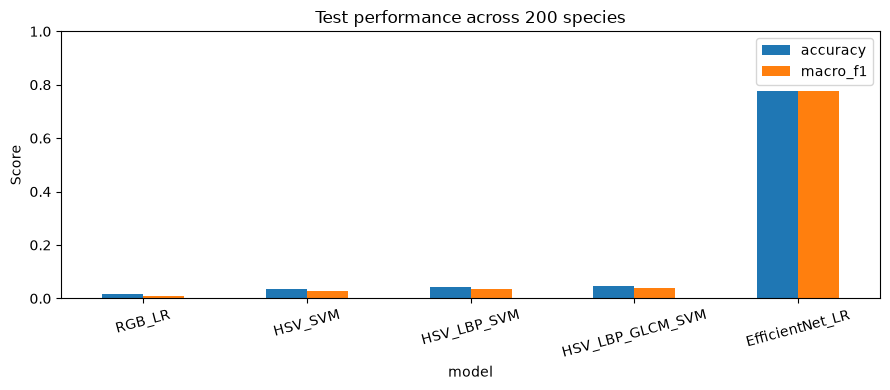

In [11]:
test_features = {
    'RGB_LR': rgb_test,
    'HSV_SVM': hsv_test,
    'HSV_LBP_SVM': np.concatenate([hsv_test, lbp_test], axis=1),
    'HSV_LBP_GLCM_SVM': np.concatenate([hsv_test, lbp_test, glcm_test], axis=1),
    'EfficientNet_LR': cnn_test,
}
predictions = test[['image_id', 'class_id']].copy()
metric_rows = []
for name, model in models.items():
    predicted = model.predict(test_features[name])
    predictions[name] = predicted
    precision, recall, f1, _ = precision_recall_fscore_support(
        test['class_id'], predicted, labels=class_ids, average='macro', zero_division=0)
    metric_rows.append({'model': name, 'accuracy': accuracy_score(test['class_id'], predicted),
                        'macro_precision': precision, 'macro_recall': recall, 'macro_f1': f1})
results = pd.DataFrame(metric_rows).set_index('model')
predictions.to_csv(OUTPUT / 'test_predictions.csv', index=False)
results.to_csv(OUTPUT / 'test_metrics.csv')
display(results.round(4))

ax = results[['accuracy', 'macro_f1']].plot.bar(figsize=(9, 4), ylim=(0, 1), rot=15)
ax.set_title(f'Test performance across {len(class_ids)} species')
ax.set_ylabel('Score')
plt.tight_layout()
plt.savefig(OUTPUT / 'model_comparison.png', dpi=150)
plt.show()
plt.close()

## 9. Error Analysis: Confusion Matrices, Species Co-occurrence, and Example Grids
In addition to the 10-Warbler confusion view, we extract the **Top-10 off-diagonal species confusion pairs** across all `200` classes (`results_v2/top_confusion_pairs.csv`) and inspect sample test predictions (`results_v2/*_examples.png`):

- **Baseline (`RGB_LR`, macro-F1 `0.0097`):** Collapses heavily onto background-dominated classes (for example predicting *Spotted Catbird* across multiple unrelated species).
- **Conventional colour + texture (`HSV_LBP_GLCM_SVM`, macro-F1 `0.0388`):** Distinguishes coarse colour palettes better than RGB, but still confuses visually distinct birds with similar overall colour ratios (*Hooded Oriole* -> *Baltimore Oriole*: 8; *Blue Grosbeak* -> *Painted Bunting*: 8; *Gadwall* -> *Red-breasted Merganser*: 8).
- **Frozen CNN (`EfficientNet_LR`, macro-F1 `0.7768`):** Resolves background and coarse colour ambiguity, leaving mostly genuine fine-grained sibling-species confusions within the same genus (*Anna's Hummingbird* -> *Ruby-throated Hummingbird*: 9; *Elegant Tern* -> *Caspian Tern*: 8; *Acadian Flycatcher* -> *Yellow-bellied Flycatcher*: 8; *Barn Swallow* -> *Bank Swallow* and *Golden-winged* -> *Blue-winged Warbler* in the example grid).

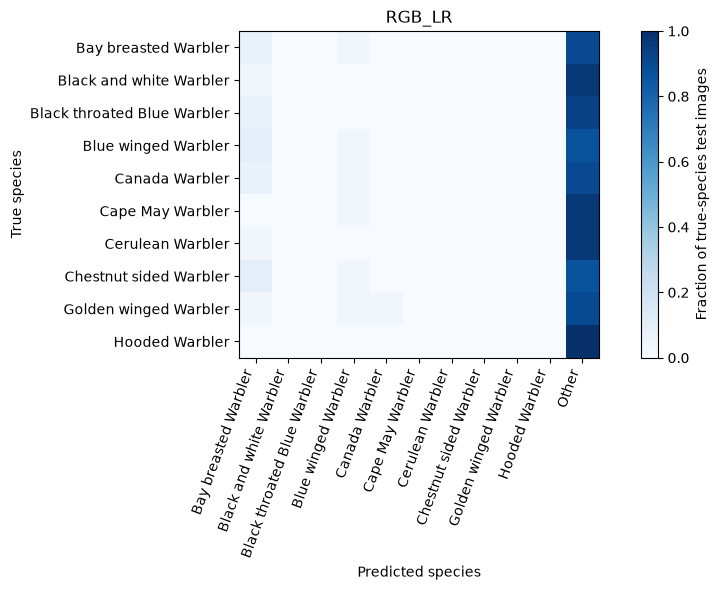

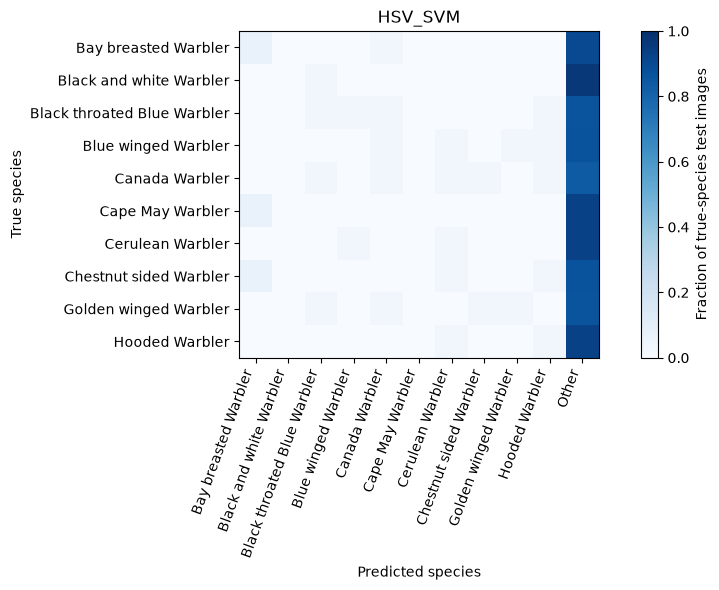

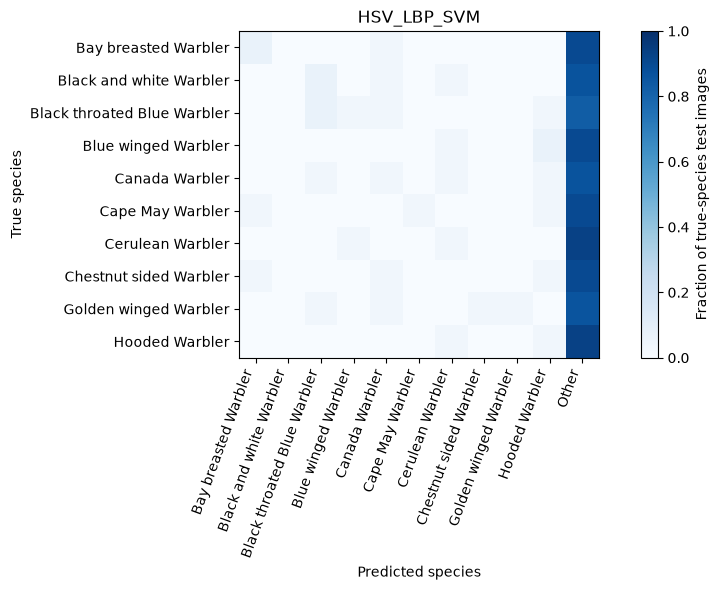

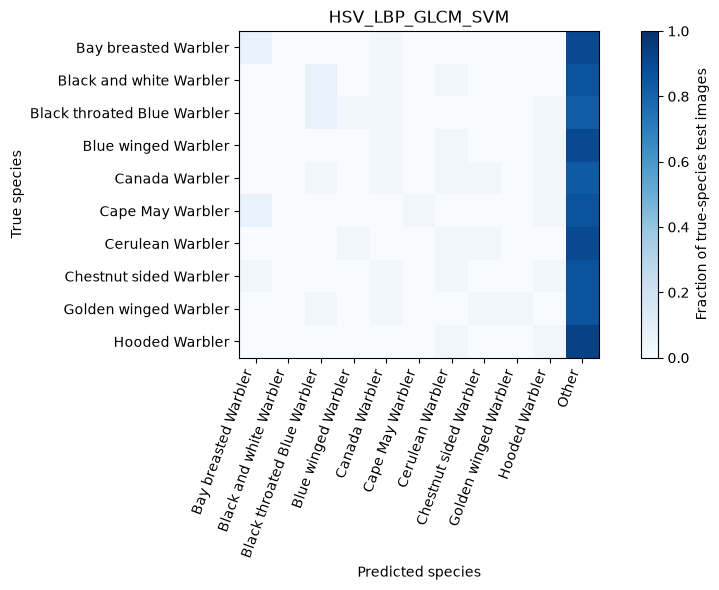

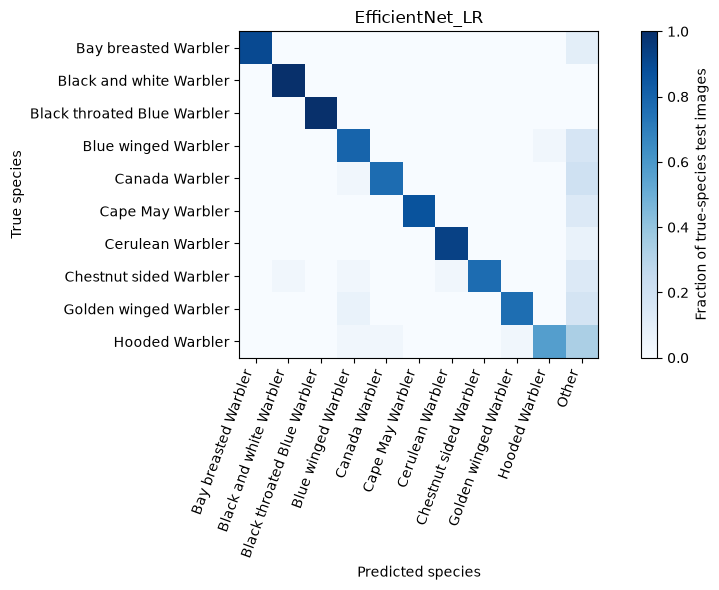

Top-10 confused species pairs (HSV_LBP_GLCM_SVM vs EfficientNet_LR):


,model,true_species,predicted_species,count
30,HSV_LBP_GLCM_SVM,Hooded Oriole,Baltimore Oriole,8
31,HSV_LBP_GLCM_SVM,Blue Grosbeak,Painted Bunting,8
32,HSV_LBP_GLCM_SVM,Gadwall,Red breasted Merganser,8
33,HSV_LBP_GLCM_SVM,Scarlet Tanager,Baltimore Oriole,8
34,HSV_LBP_GLCM_SVM,Purple Finch,Pine Grosbeak,7
35,HSV_LBP_GLCM_SVM,Pacific Loon,Red breasted Merganser,6
36,HSV_LBP_GLCM_SVM,Black footed Albatross,Rhinoceros Auklet,6
37,HSV_LBP_GLCM_SVM,Red breasted Merganser,Black footed Albatross,5
38,HSV_LBP_GLCM_SVM,Cardinal,Vermilion Flycatcher,5
39,HSV_LBP_GLCM_SVM,American Pipit,Geococcyx,5


In [12]:
names = classes.set_index('class_id')['class_name'].to_dict()
def bird_name(class_id):
    return names[int(class_id)].split('.', 1)[1].replace('_', ' ')

positions = [list(class_ids).index(c) for c in warbler_ids]
pair_rows = []
for name in models:
    matrix = confusion_matrix(test['class_id'], predictions[name], labels=class_ids)
    pd.DataFrame(matrix, index=class_ids, columns=class_ids).to_csv(OUTPUT / f'{name}_confusion.csv')
    report = classification_report(test['class_id'], predictions[name], labels=class_ids,
                                    target_names=[bird_name(c) for c in class_ids],
                                    output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(OUTPUT / f'{name}_per_species.csv')

    off_diag = matrix.copy()
    np.fill_diagonal(off_diag, 0)
    top_idx = np.argsort(off_diag.ravel())[::-1][:10]
    for flat_idx in top_idx:
        r, c = divmod(flat_idx, len(class_ids))
        if off_diag[r, c] > 0:
            pair_rows.append({'model': name, 'true_species': bird_name(class_ids[r]),
                              'predicted_species': bird_name(class_ids[c]), 'count': int(off_diag[r, c])})

    selected = matrix[np.ix_(positions, positions)]
    other = matrix[positions].sum(axis=1) - selected.sum(axis=1)
    shown = np.column_stack([selected, other]) / matrix[positions].sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(10, 6))
    plot = ax.imshow(shown, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(warbler_ids) + 1), [bird_name(c) for c in warbler_ids] + ['Other'], rotation=70, ha='right')
    ax.set_yticks(range(len(warbler_ids)), [bird_name(c) for c in warbler_ids])
    ax.set(xlabel='Predicted species', ylabel='True species', title=name)
    fig.colorbar(plot, ax=ax, label='Fraction of true-species test images')
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{name}_warbler_confusion.png', dpi=150)
    plt.show()
    plt.close(fig)

top_pairs = pd.DataFrame(pair_rows)
top_pairs.to_csv(OUTPUT / 'top_confusion_pairs.csv', index=False)
print('Top-10 confused species pairs (HSV_LBP_GLCM_SVM vs EfficientNet_LR):')
display(top_pairs[top_pairs['model'].isin(['HSV_LBP_GLCM_SVM', 'EfficientNet_LR'])])

In [13]:
for name in ['RGB_LR', 'HSV_LBP_GLCM_SVM', 'EfficientNet_LR']:
    correct = predictions[name].to_numpy() == test['class_id'].to_numpy()
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout='constrained')
    for row_number, is_correct in enumerate([True, False]):
        available = np.flatnonzero(correct == is_correct)
        chosen = rng.choice(available, size=min(3, len(available)), replace=False)
        for ax in axes[row_number]:
            ax.axis('off')
        for ax, index in zip(axes[row_number], chosen):
            row = test.iloc[index]
            with Image.open(data_folder / 'images' / row.filename) as picture:
                ax.imshow(picture.convert('RGB'))
            ax.set_title(f'True: {bird_name(row.class_id)}\nPred: {bird_name(predictions[name].iloc[index])}',
                         color='green' if is_correct else 'red', fontsize=9)
    fig.suptitle(f'{name}: correct (top) vs mistakes (bottom)')
    fig.savefig(OUTPUT / f'{name}_examples.png', dpi=120)
    plt.close(fig)
print('Saved prediction example grids to:', OUTPUT.name)

Saved prediction example grids to: results_v2


## 10. Summary and Environment Settings
**Key findings (`5,794`-image official test set, `200` species):**
- **Progression:** `RGB_LR` (`0.0097` macro-F1) < `HSV_SVM` (`0.0287`) < `HSV_LBP_SVM` (`0.0351`, `+0.0064`) < `HSV_LBP_GLCM_SVM` (`0.0388`, `+0.0038`) < `EfficientNet_LR` (`0.7768`, `77.58%` accuracy).
- **Solver stability:** Pairing `StandardScaler()` with `Normalizer('l2')` and `LinearSVC(dual=True)` resolved prior non-convergence on sparse histogram bins—all `20/20` validation trials converged in `~47-49s` per SVM model (`results_v2/validation_trials.csv`).
- **Limitations:** Global colour/texture histograms mix background pixels (sky, foliage, water) with the bird; ImageNet-pretrained weights may overlap with CUB-200-2011 photographs; and metrics are measured on one fixed split (`SEED = 42`).

In [14]:
print('Species:', len(class_ids), '| Splits:', len(train), len(validation), len(test))
print('Best test macro-F1:', results['macro_f1'].idxmax(), round(results['macro_f1'].max(), 4))
lbp_delta = results.loc['HSV_LBP_SVM', 'macro_f1'] - results.loc['HSV_SVM', 'macro_f1']
glcm_delta = results.loc['HSV_LBP_GLCM_SVM', 'macro_f1'] - results.loc['HSV_LBP_SVM', 'macro_f1']
print(f'LBP delta over HSV: {lbp_delta:+.4f} | GLCM delta over HSV+LBP: {glcm_delta:+.4f}')

pd.Series(feature_times, name='seconds').to_csv(OUTPUT / 'feature_times.csv')
trial_table = pd.DataFrame(trial_rows)
display(trial_table.groupby('model')['fit_seconds'].sum().rename('total_tuning_seconds'))

settings = {
    'seed': SEED, 'C_values': C_VALUES, 'max_iterations': MAX_ITERATIONS,
    'species': int(len(class_ids)), 'split_sizes': [len(train), len(validation), len(test)],
    'histogram_size': [128, 128], 'rgb_bins': 16, 'hsv_bins': [8, 8, 8],
    'lbp': {'points': 8, 'radius': 1, 'method': 'uniform'},
    'glcm': {'levels': 32, 'distances': [1, 3], 'props': list(GLCM_PROPS)},
    'cnn_weights': str(weights), 'device': str(DEVICE), 'cpu_threads': CPU_THREADS,
    'python': platform.python_version(),
    'process_memory_mb': round(psutil.Process().memory_info().rss / 1024**2, 1),
    'versions': {p: version(p) for p in ['numpy', 'pandas', 'Pillow', 'scikit-learn',
                                        'scikit-image', 'torch', 'torchvision']},
}
(OUTPUT / 'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
print('Saved results to:', OUTPUT.name)

Species: 200 | Splits: 4795 1199 5794
Best test macro-F1: EfficientNet_LR 0.7768
LBP delta over HSV: +0.0064 | GLCM delta over HSV+LBP: +0.0038


model
EfficientNet_LR     45.251036
HSV_LBP_GLCM_SVM    49.097409
HSV_LBP_SVM         47.317172
HSV_SVM             48.746541
RGB_LR               0.438006
Name: total_tuning_seconds, dtype: float64

Saved results to: results_v2
